In [1]:
# conda vis2
from pathlib import Path
PROJECT_ROOT = Path().resolve().parent.parent.parent
EXPERIMENT = PROJECT_ROOT / 'experiments' / 'CAMP2Ex_RF17' / 'V06' / 'default'
ITERATIONS = EXPERIMENT / 'iterations'
INTERIM_DATA = PROJECT_ROOT / 'data' / 'interim'
FIGURE_OUT = PROJECT_ROOT / 'figures'

import sys
sys.path.append(str(PROJECT_ROOT))

import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import at3d
import glob

savefig = False
fig_version = 'V03'

In [2]:
def calculate_cloud_elements(ext, alt, time):
    """
    Calculate mean extinction, mean altitude, and total time for each cloud element.

    Parameters:
        ext (np.ndarray): Array of extinction values.
        alt (np.ndarray): Array of altitude values.
        time (np.ndarray): Array of time values.

    Returns:
        tuple: Three lists containing mean extinction, mean altitude, and total time
               for each cloud element.
    """
    mean_ext_list = []
    mean_alt_list = []
    tot_time_list = []
    start_idx = None

    for i in range(len(ext)):
        if not np.isnan(ext[i]):
            if start_idx is None:
                start_idx = i
        else:
            if start_idx is not None:
                # Process the cloud element
                mean_ext = np.nanmean(ext[start_idx:i])
                mean_alt = np.nanmean(alt[start_idx:i])
                total_time = (time[i] - time[start_idx]) / np.timedelta64(1, 's')
                mean_ext_list.append(mean_ext)
                mean_alt_list.append(mean_alt)
                tot_time_list.append(total_time)
                start_idx = None

    # Handle the last cloud element if it ends at the end of the array
    if start_idx is not None:
        mean_ext = np.nanmean(ext[start_idx:])
        mean_alt = np.nanmean(alt[start_idx:])
        total_time = (time[-1] - time[start_idx]) / np.timedelta64(1, 's')
        mean_ext_list.append(mean_ext)
        mean_alt_list.append(mean_alt)
        tot_time_list.append(total_time)
    return np.array(mean_ext_list), np.array(mean_alt_list), np.array(tot_time_list)


In [3]:
p3_file = INTERIM_DATA / 'CAMP2Ex_SPEC_RF17_preprocessed.nc'
p3 = xr.load_dataset(p3_file)
p3 = p3.sel(time=slice('2019-10-02T00:00:00', '2019-10-02T01:50:00'))

pad = 3 #km

iter_files = sorted(ITERATIONS.glob('iter*.nc'))
sensors, solvers, rte_grid = at3d.util.load_forward_model(iter_files[-1])
cloud = solvers[0.67].medium['cloud']
cloud = cloud.sel(
    x=slice(np.min(cloud.x.data) + pad, np.max(cloud.y.data) - pad),
    y=slice(np.min(cloud.y.data) + pad, np.max(cloud.y.data) - pad)
)
X, Y, Z = np.meshgrid(cloud.x.data, cloud.y.data, cloud.z.data, indexing='ij')
cloud = cloud.assign_coords(Z=np.ravel(Z))
cloud['ext_ravel'] = (['Z'], np.ravel(cloud.extinction.data))

/data/keeling/a/johntl3/miniconda3/envs/vis2/lib/python3.10/site-packages/xarray/core/concat.py:500: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  common_dims = tuple(pd.unique([d for v in vars for d in v.dims]))
/data/keeling/a/johntl3/miniconda3/envs/vis2/lib/python3.10/site-packages/at3d/solver.py:2337: UserWarning: Number of SHDOM grid cells with optical depth greater than 2: '128'. Max cell optical depth: '3.9491629600524902'
  warnings.warn("Number of SHDOM grid cells with optical depth greater than 2: '{}'. "


## Figure 11: CAMP2Ex in-situ comparison

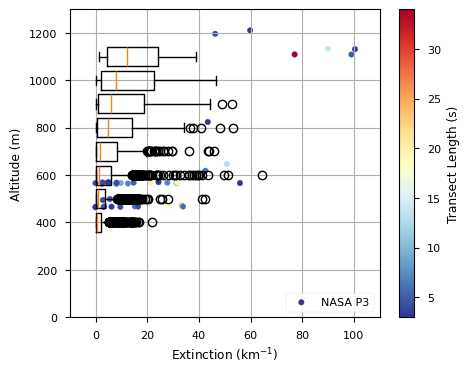

In [4]:
plt.style.use('seaborn-v0_8-paper')
thresh = 0
f, ax = plt.subplots(1, 1, figsize=(5, 4))

ax.grid()

cloud_cond = cloud.ext_ravel.data > thresh
ext_cloud = cloud.ext_ravel.data[cloud_cond]
z_cloud = cloud.Z.data[cloud_cond]

positions = []
ext_box = []
for z in cloud.z.data:
    ext_box.append(ext_cloud[z_cloud == z])
    positions.append(int(z*1000))
ax.boxplot(ext_box, positions=positions, widths=80, vert=False, manage_ticks=False)

ce_ext, ce_alt, ce_time = calculate_cloud_elements(
    p3.ext_km.data,
    p3.GPS_Altitude.data,
    p3.time.data
)
s = ax.scatter(ce_ext, ce_alt, c=ce_time, label='NASA P3', s=16, cmap='RdYlBu_r')
plt.colorbar(s, ax=ax, label='Transect Length (s)')

ax.set_xlabel('Extinction (1/km)')
ax.set_ylabel('Altitude (m)')
# ax.grid()
# ax.legend()

ax.set_xlim([-10, 110])
ax.set_ylim([0, 1300])
ax.set_xlabel(r'Extinction (km$^{-1}$)')
ax.legend(loc='lower right')

plt.savefig(
    FIGURE_OUT / '{}_figure11_insitu_comparison.png'.format(fig_version),
    format='png',
    dpi=300,
    bbox_inches='tight',
    transparent=False
)

Text(0.5, 0, 'Extinction (km$^{-1}$)')

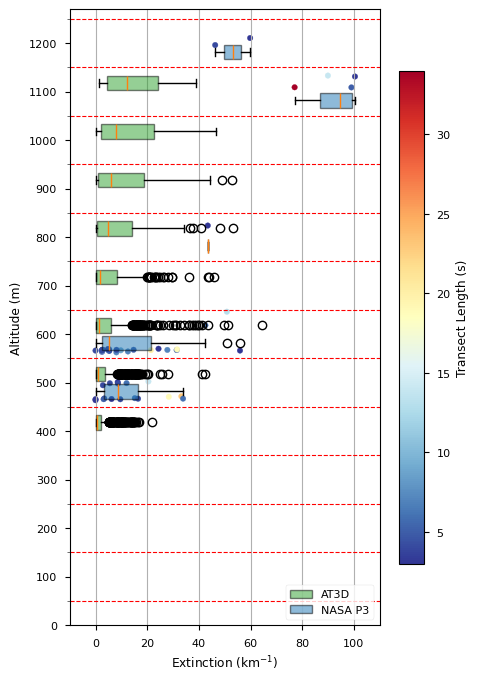

In [5]:
plt.style.use('seaborn-v0_8-paper')
thresh = 0
f, ax = plt.subplots(1, 1, figsize=(5, 8))

cloud_cond = cloud.ext_ravel.data > thresh
ext_cloud = cloud.ext_ravel.data[cloud_cond]
z_cloud = cloud.Z.data[cloud_cond]

positions = []
ext_box = []
for z in cloud.z.data:
    ext_box.append(ext_cloud[z_cloud == z])
    positions.append(int(z*1000))
at3d_bplot = ax.boxplot(ext_box, positions=np.array(positions)+18, widths=30, vert=False, manage_ticks=False, patch_artist=True)
for patch in at3d_bplot['boxes']:
    patch.set_facecolor('tab:green')
    patch.set_alpha(0.5)

ce_ext, ce_alt, ce_time = calculate_cloud_elements(
    p3.ext_km.data,
    p3.GPS_Altitude.data,
    p3.time.data
)

p3_ext_box = []
for pos in positions:
    cond = (ce_alt > pos-50) & (ce_alt <= pos+50)
    p3_ext_box.append(ce_ext[cond])
p3_bplot = ax.boxplot(p3_ext_box, positions=np.array(positions)-18, widths=30, vert=False, manage_ticks=False, patch_artist=True)
for patch in p3_bplot['boxes']:
    patch.set_facecolor('tab:blue')
    patch.set_alpha(0.5)

ax.legend([at3d_bplot['boxes'][0], p3_bplot['boxes'][0]], ['AT3D', 'NASA P3'], loc='lower right')

s = ax.scatter(ce_ext, ce_alt, c=ce_time, label='NASA P3', s=16, cmap='RdYlBu_r')
plt.colorbar(s, ax=ax, label='Transect Length (s)', shrink=0.8)

ax.set_xlabel('Extinction (1/km)')
ax.set_ylabel('Altitude (m)')
ax.grid(visible=True, which='major', axis='x')
ax.grid(visible=True, which='minor', axis='y', color='r', linestyle='--')

ax.set_yticks(np.arange(0, 1400, 100))
ax.set_yticks(np.arange(50, 1300, 100), minor=True)
ax.set_xlim([-10, 110])
ax.set_ylim([0, 1270])
ax.set_xlabel(r'Extinction (km$^{-1}$)')

# plt.savefig(
#     FIGURE_OUT / '{}_figure11_insitu_comparison.png'.format(fig_version),
#     format='png',
#     dpi=300,
#     bbox_inches='tight',
#     transparent=False
# )

In [6]:
from scipy.stats import ks_2samp
i = 5
d_stat, p_value = ks_2samp(p3_ext_box[i], ext_box[i])

print('{:<10} | {:<14} | {:<14}'.format('Alt', 'D-stat', 'p-value'))
for i in range(len(p3_ext_box)):
    if((len(p3_ext_box[i]) > 0) & (len(ext_box[i]) > 0)):
        d_stat, p_value = ks_2samp(p3_ext_box[i], ext_box[i])
        print('{:<10} | {:<14.8f} | {:<14.8f}'.format(i, d_stat, p_value))

Alt        | D-stat         | p-value       
5          | 0.59632911     | 0.00000347    
6          | 0.56829152     | 0.00000000    
8          | 0.99086758     | 0.02727273    
11         | 1.00000000     | 0.00041280    


In [7]:
from scipy.stats import ttest_ind

print('{:<10} | {:<14} | {:<14}'.format('Alt', 't-stat', 'p-value', 'df'))
for i in range(len(p3_ext_box)):
    if((len(p3_ext_box[i]) > 0) & (len(ext_box[i]) > 0)):
        result = ttest_ind(p3_ext_box[i], ext_box[i])
        t_stat = result.statistic
        p_value = result.pvalue
        print('{:<10} | {:<14.8f} | {:<14.8f}'.format(i, t_stat, p_value))

Alt        | t-stat         | p-value       
5          | 7.94983799     | 0.00000000    
6          | 5.99440875     | 0.00000000    
8          | 3.22686210     | 0.00144427    
11         | 11.27610114    | 0.00000000    


In [8]:
result

TtestResult(statistic=11.27610113858438, pvalue=1.3648510274305952e-09, df=18.0)